In [ ]:
!gdown 1UrPILaGrqmpYG_EsZWTjoxkcfySS2_su

Downloading...
From (original): https://drive.google.com/uc?id=1UrPILaGrqmpYG_EsZWTjoxkcfySS2_su
From (redirected): https://drive.google.com/uc?id=1UrPILaGrqmpYG_EsZWTjoxkcfySS2_su&confirm=t&uuid=eb05a1a2-dfe2-4449-b749-2da3603d4f7f
To: /content/audio_uz.zip
100% 41.7M/41.7M [00:01<00:00, 22.2MB/s]


In [ ]:
!unzip audio_uz.zip

Archive:  audio_uz.zip
   creating: audio_uz/
  inflating: audio_uz/0_AkmalAshirmatov_0.wav  
  inflating: audio_uz/0_AkmalAshirmatov_1.wav  
  inflating: audio_uz/0_AkmalAshirmatov_10.wav  
  inflating: audio_uz/0_AkmalAshirmatov_11.wav  
  inflating: audio_uz/0_AkmalAshirmatov_12.wav  
  inflating: audio_uz/0_AkmalAshirmatov_13.wav  
  inflating: audio_uz/0_AkmalAshirmatov_14.wav  
  inflating: audio_uz/0_AkmalAshirmatov_15.wav  
  inflating: audio_uz/0_AkmalAshirmatov_16.wav  
  inflating: audio_uz/0_AkmalAshirmatov_17.wav  
  inflating: audio_uz/0_AkmalAshirmatov_18.wav  
  inflating: audio_uz/0_AkmalAshirmatov_19.wav  
  inflating: audio_uz/0_AkmalAshirmatov_2.wav  
  inflating: audio_uz/0_AkmalAshirmatov_20.wav  
  inflating: audio_uz/0_AkmalAshirmatov_21.wav  
  inflating: audio_uz/0_AkmalAshirmatov_22.wav  
  inflating: audio_uz/0_AkmalAshirmatov_3.wav  
  inflating: audio_uz/0_AkmalAshirmatov_4.wav  
  inflating: audio_uz/0_AkmalAshirmatov_5.wav  
  inflating: audio_uz/0_Akmal

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import IPython.display as ipd
import librosa
import librosa.display
import soundfile as sf

In [ ]:
def add_white_noise(signal, noise_percentage_factor):
  noise = np.random.normal(0, signal.std(), signal.size)
  augmented_signal = signal + noise * noise_percentage_factor
  return augmented_signal

In [ ]:
def pitch_scale(signal, sr, num_semitones = 2):
  return librosa.effects.pitch_shift(signal, sr=sr, n_steps = num_semitones)

In [ ]:
import os
audio_files = os.listdir('audio_uz')
len(audio_files)

1024

In [ ]:
for i in range(len(audio_files)):
  digit_number = audio_files[i].split("_")[0]
  audio_name = audio_files[i].split("_")[1]
  sample_number = audio_files[i].split("_")[2]

  #loading the existing audio
  signal, sr = librosa.load(f'audio_uz/' + audio_files[i])

  signal_noise = add_white_noise(signal, 0.03)
  signal_pitch3 = pitch_scale(signal, sr, -3)
  signal_pitch1 = pitch_scale(signal, sr, -1)

  signal_noise_file_name = digit_number + '_noise' + audio_name + '_' + sample_number
  signal_pitch3_file_name = digit_number + '_pitch3' + audio_name + '_' + sample_number
  signal_pitch1_file_name = digit_number + '_pitch1' + audio_name + '_' + sample_number

  sf.write(f'audio_uz/' + signal_noise_file_name, signal_noise, sr)
  sf.write(f'audio_uz/' + signal_pitch3_file_name, signal_pitch3, sr)
  sf.write(f'audio_uz/' + signal_pitch1_file_name, signal_pitch1, sr)


In [ ]:
import os
audio_files = os.listdir('audio_uz')
len(audio_files)

4096

In [ ]:
from os import listdir
from os.path import isfile, join
from matplotlib import pyplot as plt
import scipy.io.wavfile as wav
from keras.preprocessing import image
from keras.utils import to_categorical

In [ ]:
def wav_to_spectrogram(audio_path, save_folder, spectrogram_dimensions = (64, 64), noverlap=16, cmap='gray_r'):
    sample_rate, samples = wav.read(audio_path)
    fig = plt.figure()
    fig.set_size_inches((spectrogram_dimensions[0]/fig.get_dpi(), spectrogram_dimensions[1]/fig.get_dpi()))
    ax = plt.Axes(fig, [0., 0., 1., 1.])
    ax.set_axis_off()
    fig.add_axes(ax)
    ax.specgram(samples, cmap=cmap, Fs=2, noverlap=noverlap)
    ax.xaxis.set_major_locator(plt.NullLocator())
    ax.yaxis.set_major_locator(plt.NullLocator())
    fig.savefig(save_folder, bbox_inches="tight", pad_inches=0)
    plt.close()

In [ ]:
from librosa.core.constantq import audio
def dir_to_spectrograms(audio_dir, spectrogram_dir, spectrogram_dimensions = (64, 64), noverlap=16, cmap='gray_r'):
    file_names = [f for f in listdir(audio_dir) if isfile(join(audio_dir, f)) and '.wav' in f]
    for file_name in file_names:
      print(file_name)
      audio_path = audio_dir + file_name
      spectrogram_path = spectrogram_dir + file_name.replace('.wav', '.png')
      wav_to_spectrogram(audio_path, spectrogram_path, spectrogram_dimensions=spectrogram_dimensions, noverlap=noverlap, cmap=cmap)


In [ ]:
import os

# Agar '/content/spectrograms' oddiy fayl bo'lsa, o'chirib tashlaymiz
if os.path.exists('/content/spectrograms') and not os.path.isdir('/content/spectrograms'):
    os.remove('/content/spectrograms')

# Spectrogram papkasini qaytadan yaratamiz
os.makedirs('/content/spectrograms', exist_ok=True)

In [ ]:
def dir_to_spectrograms(audio_dir, spectrogram_dir, spectrogram_dimensions = (64, 64), noverlap=16, cmap='gray_r'):
    file_names = [f for f in listdir(audio_dir) if isfile(join(audio_dir, f)) and '.wav' in f]
    for file_name in file_names:
      audio_path = join(audio_dir, file_name)
      spectrogram_path = join(spectrogram_dir, file_name.replace('.wav', '.png'))
      wav_to_spectrogram(audio_path, spectrogram_path, spectrogram_dimensions=spectrogram_dimensions, noverlap=noverlap, cmap=cmap)

In [ ]:
audio_folder = 'audio_uz/'
spectrogram_folder = '/content/spectrograms'
dir_to_spectrograms(audio_folder, spectrogram_folder)

/usr/local/lib/python3.13/dist-packages/matplotlib/axes/_axes.py:8233: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


In [ ]:
audio_folder = 'audio_uz/'
spectrogram_folder = '/content/spectrograms'
dir_to_spectrograms(audio_folder, spectrogram_folder)

In [ ]:
from keras.preprocessing import image
from keras.utils import to_categorical


In [ ]:
imagesDir = "spectrograms/"
trainset = []
testset = []
for file in os.listdir(imagesDir):
  label = file.split('_')[0]
  sample_number = file.split('_')[2]
  img = image.load_img(imagesDir + file)
  if sample_number in ['0.png', '1.png']:
    testset.append([np.array(img), label])
  else:
    trainset.append([np.array(img), label])

In [ ]:
len(trainset)

3656

In [ ]:
len(testset)

440

In [ ]:
#Get only images in the train list not the labels
X_train = np.array([i[0] for i in trainset])
#Get only labels in the train list
y_train = np.array([i[1] for i in trainset])

X_test = np.array([i[0] for i in testset])
y_test = np.array([i[1] for i in testset])
#

In [ ]:
X_train = np.asanyarray(X_train)
y_train = np.asanyarray(y_train)
X_test = np.asanyarray(X_test)
y_test = np.asanyarray(y_test)

array([[[145, 145, 145],
        [145, 145, 145],
        [153, 153, 153],
        ...,
        [152, 152, 152],
        [155, 155, 155],
        [145, 145, 145]],

       [[145, 145, 145],
        [146, 146, 146],
        [149, 149, 149],
        ...,
        [156, 156, 156],
        [157, 157, 157],
        [149, 149, 149]],

       [[140, 140, 140],
        [150, 150, 150],
        [156, 156, 156],
        ...,
        [154, 154, 154],
        [155, 155, 155],
        [149, 149, 149]],

       ...,

       [[ 74,  74,  74],
        [ 73,  73,  73],
        [ 83,  83,  83],
        ...,
        [ 80,  80,  80],
        [ 79,  79,  79],
        [ 84,  84,  84]],

       [[ 61,  61,  61],
        [ 52,  52,  52],
        [ 57,  57,  57],
        ...,
        [ 64,  64,  64],
        [ 61,  61,  61],
        [ 67,  67,  67]],

       [[ 75,  75,  75],
        [ 72,  72,  72],
        [ 69,  69,  69],
        ...,
        [ 54,  54,  54],
        [ 56,  56,  56],
        [ 63,  63,  63]]], dtype=uint8)
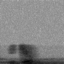

In [ ]:
X_test[0]

In [ ]:
#Convert to one hot representaion
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# Convert to float and normalize
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [ ]:
y_test[0]

array([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])

In [ ]:
from keras.models import Sequential
from keras import optimizers
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization
from keras import models

In [ ]:
data_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])

In [ ]:
model = Sequential()
model.add(Conv2D(32, kernel_size=(2, 2), activation='relu', input_shape=data_shape))
model.add(BatchNormalization())
model.add(Conv2D(64, kernel_size=(2, 2), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())

model.add(Dense(64, activation='relu'))
model.add(Dense(256, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(10, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 63, 63, 32)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 63, 63, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 62, 62, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 62, 62, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61504)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,936,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         4,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,966,298 (15.13 MB)

 Trainable params: 3,966,106 (15.13 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
import os
import numpy as np
from keras.preprocessing import image
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization
from keras.utils import to_categorical

# 1. Ma'lumotlarni qayta yuklash va tayyorlash
imagesDir = "spectrograms/"
trainset = []
testset = []
for file in os.listdir(imagesDir):
    label = file.split('_')[0]
    sample_number = file.split('_')[2]
    img = image.load_img(imagesDir + file)
    if sample_number in ['0.png', '1.png']:
        testset.append([np.array(img), label])
    else:
        trainset.append([np.array(img), label])

X_train = np.array([i[0] for i in trainset])
y_train = np.array([i[1] for i in trainset])
X_test = np.array([i[0] for i in testset])
y_test = np.array([i[1] for i in testset])

# float32 formatga o'tkazish va normallashtirish
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Nishonlarni (labels) to'g'ri one-hot formatiga o'tkazish
y_train_int = np.array([int(i) for i in y_train])
test_labels_int = np.array([int(i) for i in y_test])
y_train_cat = to_categorical(y_train_int, num_classes=10)
y_test_cat = to_categorical(test_labels_int, num_classes=10)

data_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])

# 2. Yangi mukammal CNN model arxitekturasi
model = Sequential([
    Input(shape=data_shape),

    Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Modelni qayta o'qitish
history = model.fit(X_train, y_train_cat, batch_size=32, validation_split=0.2, epochs=30, verbose=1)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 96ms/step - accuracy: 0.1194 - loss: 3.4502 - val_accuracy: 0.0956 - val_loss: 3.4147
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1019 - loss: 2.2821 - val_accuracy: 0.1216 - val_loss: 3.8475
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1221 - loss: 2.2836 - val_accuracy: 0.1148 - val_loss: 3.4144
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1231 - loss: 2.2572 - val_accuracy: 0.1120 - val_loss: 2.5181
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1361 - loss: 2.2585 - val_accuracy: 0.1298 - val_loss: 2.2691
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1375 - loss: 2.2315 - val_accuracy: 0.1175 - val_loss: 2.3192
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1495 - loss: 2.2130 - val_accuracy: 0.1243 - val_loss: 2.2516
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1587 - loss: 2.1808 - val_accuracy: 0.0997 - val_los

In [ ]:
model.evaluate(X_test, y_test_cat)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.3977 - loss: 1.7550


[1.754992127418518, 0.39772728085517883]

In [ ]:
index = 322
print('ground Truth', np.argmax(y_test_cat[index]))
print('prediction', np.argmax(model.predict(X_test)[index].reshape(1, -1)))

ground Truth 5
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
prediction 3


## Yangi pipeline: log-mel spektrogramma (PNG'siz)

Eski model 30 epoch davomida **accuracy ≈ 0.10** va **loss ≈ 2.302** da qotib qoldi. 2.302 = ln(10) — bu 10 sinfning har biriga 10% ehtimol beradigan, ya'ni **hech narsa o'rganmagan** modelning loss'i. Shuning uchun u hamma audioga bir xil javob ("3") berdi.

Muammo modelda emas, datada edi:
- `wav_to_spectrogram` 8 kHz audio uchun yozilgan: raqam rasmning pastki ingichka qismiga siqilib, qolgani shovqin bo'lib qolgan;
- augmented fayllar `librosa.load` default'i bo'yicha 22050 Hz da yozilgan, originallar esa boshqa sample rate'da bo'lishi mumkin;
- PNG orqali o'tish ma'lumotni yo'qotadi (8-bit, har rasmga alohida kontrast, 3 ta bir xil RGB kanal).

Quyidagi kataklar audioni to'g'ridan-to'g'ri sonli log-mel matritsaga aylantiradi.

### 1. Diagnostika: sample rate va davomiylik
Original va augmented fayllarning sample rate'i, kanal soni va davomiyligini solishtiradi. Originallarning davomiyligi `DURATION` ni tanlashga yordam beradi.

In [ ]:
# Original va augmented fayllarning sample rate, kanal soni va davomiyligini solishtirish
import os
import numpy as np
import soundfile as sf

for f in ['0_AkmalAshirmatov_5.wav', '0_noiseAkmalAshirmatov_5.wav',
          '3_Doston_4.wav', '3_pitch3Doston_4.wav']:
    info = sf.info(f'audio_uz/{f}')
    print(f"{f:32} sr={info.samplerate:6}  kanal={info.channels}  {info.duration:.2f}s")

# Barcha original (augmentatsiyasiz) fayllarning davomiyligi — DURATION ni tanlash uchun
orig = [f for f in os.listdir('audio_uz')
        if f.endswith('.wav') and '_noise' not in f and '_pitch' not in f]
durs = np.array([sf.info(f'audio_uz/{f}').duration for f in orig])
print(f"\nOriginallar: {len(orig)} ta | min={durs.min():.2f}s  "
      f"median={np.median(durs):.2f}s  max={durs.max():.2f}s")

0_AkmalAshirmatov_5.wav          sr=  8000  kanal=1  1.10s
0_noiseAkmalAshirmatov_5.wav     sr= 22050  kanal=1  1.10s
3_Doston_4.wav                   sr= 48000  kanal=1  1.60s
3_pitch3Doston_4.wav             sr= 22050  kanal=1  1.60s

Originallar: 1024 ta | min=0.52s  median=1.30s  max=3.31s


### 2. Audio → log-mel spektrogramma
Har bir audio bir xil holatga keltiriladi: **16 kHz, mono**, boshi va oxiridagi jimlik kesilgan, aniq **1 soniya**. Keyin 64 qatorli mel-spektrogramma olinib, dB shkalaga o'tkaziladi.

Mel shkalasi past chastotalarga ko'proq qator ajratadi — nutq ham aynan o'sha yerda. Natija PNG rasmga saqlanmaydi: `(64, 101)` o'lchamli sonli matritsa to'g'ridan-to'g'ri modelga beriladi. Whisper kabi ASR modellari ham ovozni aynan shunday log-mel spektrogrammaga aylantirib ishlaydi.

In [ ]:
# Audio faylni log-mel spektrogrammaga aylantiruvchi funksiya
import os
import numpy as np
import librosa

SR = 16000        # hamma audio bir xil sample rate'ga keltiriladi
DURATION = 1.0    # har bir audio uzunligi (soniya) — diagnostikadagi davomiylikka qarab o'zgartiring
N_MELS = 64       # chastota qatorlari soni

def audio_to_logmel(path):
    y, _ = librosa.load(path, sr=SR)                  # 16 kHz ga resample, mono
    y, _ = librosa.effects.trim(y, top_db=25)         # boshi va oxiridagi jimlikni kesish
    target = int(SR * DURATION)
    if len(y) < target:
        y = np.pad(y, (0, target - len(y)))            # qisqa bo'lsa — oxiriga nol qo'shish
    else:
        y = y[:target]                                  # uzun bo'lsa — kesish
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=512,
                                         hop_length=160, n_mels=N_MELS,
                                         fmax=4000)   # 0–4 kHz: 8 kHz yozuvlarda bundan yuqorisi yo'q
    return librosa.power_to_db(mel, ref=np.max)        # (64, 101) — dB shkalada

### 3. Train/test to'plamlarini yig'ish
Split avvalgidek qoladi: har bir spikerning **0 va 1-namunalari** (augmented nusxalari bilan birga) — test, qolganlari — train. Har bir namuna `(64, 101, 1)` shakldagi 1 kanalli matritsa. Label fayl nomining birinchi qismidan olinadi.

In [ ]:
# Barcha audio fayllardan feature yig'ish va train/test ga ajratish
X_train, y_train, X_test, y_test = [], [], [], []

for f in os.listdir('audio_uz'):
    if not f.endswith('.wav'):
        continue
    parts = f.split('_')
    label = int(parts[0])              # fayl nomidagi birinchi qism — raqam
    sample_number = parts[-1]          # "0.wav", "1.wav", ...
    feat = audio_to_logmel(os.path.join('audio_uz', f))
    if sample_number in ['0.wav', '1.wav']:
        X_test.append(feat);  y_test.append(label)
    else:
        X_train.append(feat); y_train.append(label)

X_train = np.array(X_train)[..., np.newaxis]   # (N, 64, 101, 1) — 1 kanal
X_test  = np.array(X_test)[..., np.newaxis]
y_train = np.array(y_train)
y_test  = np.array(y_test)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train'dagi har bir raqam soni:", np.bincount(y_train))

Train: (3656, 64, 101, 1)  Test: (440, 64, 101, 1)
Train'dagi har bir raqam soni: [352 368 368 364 368 368 364 368 368 368]


### 4. Har bir raqam log-mel'da qanday ko'rinadi
Har bir raqamdan bittadan namuna chiziladi. Pastki qatorlar — past chastotalar, gorizontal o'q — vaqt. Eski PNG'lardan farqli ravishda, nutq butun rasm bo'ylab aniq ko'rinishi kerak.

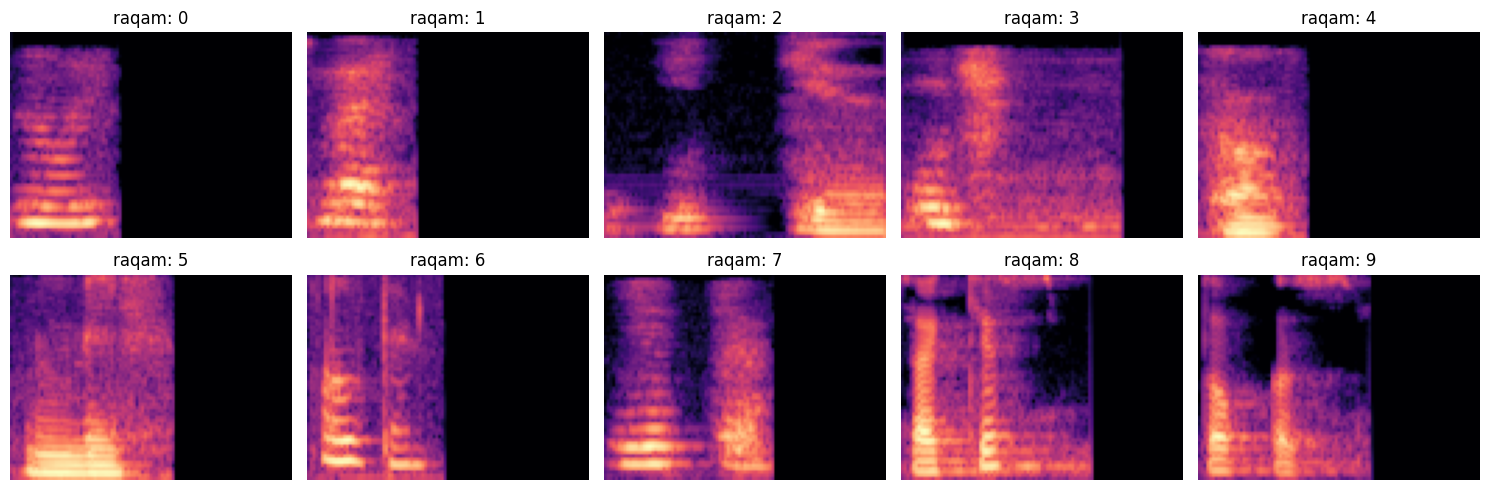

In [ ]:
# Har bir raqamdan bittadan log-mel spektrogrammani chizish
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for digit, ax in zip(range(10), axes.ravel()):
    i = np.where(y_train == digit)[0][0]          # shu raqamning birinchi namunasi
    ax.imshow(X_train[i, :, :, 0], origin='lower', aspect='auto', cmap='magma')
    ax.set_title(f"raqam: {digit}")
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5. Normallashtirish
Mean va std **faqat train'dan** olinadi va test'ga ham aynan shu qiymatlar qo'llanadi. Aks holda test statistikasi modelga sizib o'tadi (data leakage).

In [ ]:
# Train statistikasi bilan standartlashtirish
mean, std = X_train.mean(), X_train.std()    # faqat train'dan
X_train = (X_train - mean) / std
X_test  = (X_test  - mean) / std
print(f"mean={mean:.2f}  std={std:.2f}")

mean=-57.53  std=21.38


### 6. CNN model va o'qitish
Arxitektura avvalgisiga o'xshash, bitta qo'shimcha Conv bloki bilan. Label'lar butun son bo'lgani uchun `to_categorical` o'rniga `sparse_categorical_crossentropy` ishlatiladi. `validation_split` oxirgi 20% ni olgani uchun data avval aralashtiriladi. `EarlyStopping` val_loss 5 epoch yaxshilanmasa to'xtatadi va eng yaxshi og'irliklarni qaytaradi.

⚠️ Agar 1–2 epochdan keyin ham accuracy ≈ 0.10 va loss ≈ 2.30 bo'lsa — model hech narsa o'rganmayapti, 30 epochni kutmasdan datani tekshiring.

In [ ]:
# CNN modelini qurish va o'qitish
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, BatchNormalization, Flatten, Dense, Dropout
from keras.callbacks import EarlyStopping

model = Sequential([
    Input(shape=X_train.shape[1:]),                       # (64, 101, 1)
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax'),                      # 10 ta raqam
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

idx = np.random.permutation(len(X_train))                 # aralashtirish
history = model.fit(X_train[idx], y_train[idx], validation_split=0.2,
                    epochs=30, batch_size=32,
                    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 114ms/step - accuracy: 0.3868 - loss: 2.1307 - val_accuracy: 0.0915 - val_loss: 10.0822
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6286 - loss: 1.0504 - val_accuracy: 0.3333 - val_loss: 2.2504
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7199 - loss: 0.7958 - val_accuracy: 0.5656 - val_loss: 1.2590
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7811 - loss: 0.6400 - val_accuracy: 0.8156 - val_loss: 0.5966
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8266 - loss: 0.5065 - val_accuracy: 0.8675 - val_loss: 0.4257
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8338 - loss: 0.4502 - val_accuracy: 0.8948 - val_loss: 0.3100
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8581 - loss: 0.4128 - val_accuracy: 0.9098 - val_loss: 0.2904
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8789 - loss: 0.3722 - val_accuracy: 0.9208 

### 7. Test set'da baholash
Endi bashoratlar 10 ta raqam bo'ylab taqsimlanishi kerak (har biri ~44 ta), avvalgidek hammasi "3" emas. Confusion matrix qaysi raqamlar bir-biri bilan adashayotganini ko'rsatadi.

Test accuracy: 0.800   loss: 0.876
Har bir raqam necha marta bashorat qilingan: [31 41 63 54 52 41 45 35 39 39]
              precision    recall  f1-score   support

           0       0.74      0.52      0.61        44
           1       0.68      0.64      0.66        44
           2       0.62      0.89      0.73        44
           3       0.67      0.82      0.73        44
           4       0.79      0.93      0.85        44
           5       0.88      0.82      0.85        44
           6       0.93      0.95      0.94        44
           7       0.91      0.73      0.81        44
           8       1.00      0.89      0.94        44
           9       0.92      0.82      0.87        44

    accuracy                           0.80       440
   macro avg       0.81      0.80      0.80       440
weighted avg       0.81      0.80      0.80       440



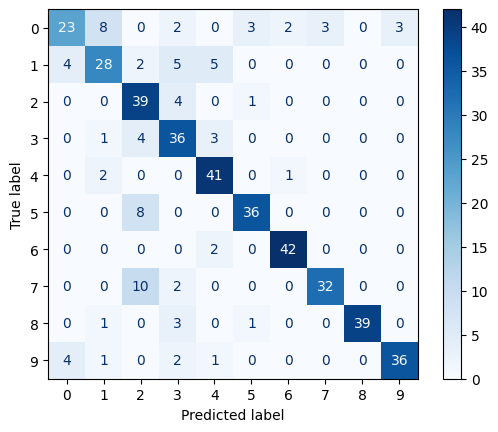

In [ ]:
# Test set'da yakuniy baho, bashoratlar taqsimoti va confusion matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.3f}   loss: {loss:.3f}")

pred = model.predict(X_test, verbose=0).argmax(axis=1)
print("Har bir raqam necha marta bashorat qilingan:", np.bincount(pred, minlength=10))

print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues')
plt.show()

## 8. Bashorat funksiyasi va uni tekshirish
`predict_digit` bitta audio faylni train'dagi bilan **aynan bir xil** tayyorlaydi: `audio_to_logmel` → train'ning `mean`/`std` si bilan normallashtirish → `(1, 64, 101, 1)` shakl. Keyin modeldan 10 ta raqamning ehtimolini oladi. Tayyorlash train'dagidan ozgina farq qilsa ham, model real audioda adashadi.

Gradio'ni ishga tushirishdan oldin funksiya test set'dagi (model ko'rmagan) bir nechta original fayl ustida tekshiriladi.

In [39]:
# Bitta audio fayl uchun bashorat — preprocessing train'dagi bilan bir xil
def predict_digit(audio_path):
    if audio_path is None:                               # Gradio'da audio berilmagan bo'lsa
        return {}
    feat = audio_to_logmel(audio_path)                    # (64, 101) — train'dagi funksiya
    feat = (feat - mean) / std                            # train'ning mean/std si bilan
    probs = model.predict(feat[np.newaxis, ..., np.newaxis], verbose=0)[0]   # (1, 64, 101, 1) -> 10 ta ehtimol
    return {str(d): float(p) for d, p in enumerate(probs)}

# Test set'dagi original fayllar (0 va 1-namunalar, augmentatsiyasiz)
test_files = sorted(f for f in os.listdir('audio_uz')
                    if f.endswith(('_0.wav', '_1.wav')) and '_noise' not in f and '_pitch' not in f)

# Tasodifiy 10 ta fayl ustida tekshiruv
for f in np.random.default_rng(0).choice(test_files, 10, replace=False):
    res = predict_digit(os.path.join('audio_uz', f))
    top = max(res, key=res.get)                           # eng katta ehtimolli raqam
    belgi = '✓' if top == f.split('_')[0] else '✗'
    print(f"{belgi} {f:28} haqiqiy={f.split('_')[0]}  bashorat={top}  ehtimol={res[top]:.2f}")

✓ 7_KamilaSaydullaeva_0.wav    haqiqiy=7  bashorat=7  ehtimol=1.00
✗ 8_AkmalAshirmatov_1.wav      haqiqiy=8  bashorat=3  ehtimol=0.99
✓ 5_KamilaSaydullaeva_1.wav    haqiqiy=5  bashorat=5  ehtimol=1.00
✓ 4_KamilaSaydullaeva_0.wav    haqiqiy=4  bashorat=4  ehtimol=1.00
✗ 2_Doston_0.wav               haqiqiy=2  bashorat=3  ehtimol=0.69
✗ 0_DiyoraSayfiddinova_0.wav   haqiqiy=0  bashorat=9  ehtimol=0.85
✓ 0_AkmalAshirmatov_1.wav      haqiqiy=0  bashorat=0  ehtimol=0.98
✓ 2_sardor_1.wav               haqiqiy=2  bashorat=2  ehtimol=1.00
✓ 1_KamilaSaydullaeva_0.wav    haqiqiy=1  bashorat=1  ehtimol=1.00
✗ 0_KamilaSaydullaeva_0.wav    haqiqiy=0  bashorat=1  ehtimol=0.91


## 9. Gradio interfeysi
Mikrofon orqali raqamni aytish yoki `.wav` fayl yuklash mumkin. Natija — eng ehtimolli 3 ta raqam. Har bir raqamdan bittadan test fayl misol sifatida qo'shilgan.

`share=True` 1 haftagacha ishlaydigan public link beradi — uni telefonda ochib, o'z ovozingiz bilan sinab ko'rishingiz mumkin. Link faqat Colab runtime ishlab turganda ishlaydi.

💡 Model faqat train'dagi spikerlar ovozida o'qigan. Yangi ovozda, ayniqsa shovqinli joyda, aniqlik pastroq bo'lishi mumkin — bu modelning haqiqiy umumlashtirish qobiliyatini ko'rsatadi.

In [44]:
# Gradio'ni o'rnatish va interfeysni ishga tushirish
!pip install -q gradio
import gradio as gr

# Har bir raqamdan bittadan test fayl — har xil spikerlardan, misol sifatida
speakers = sorted({f.split('_')[1] for f in test_files})
examples = []
for d in range(10):
    s = speakers[d % len(speakers)]                       # spikerlarni navbat bilan almashtirish
    f = next((f for f in test_files if f.startswith(f'{d}_{s}_')), None) \
        or next(f for f in test_files if f.startswith(f'{d}_'))
    examples.append([os.path.join('audio_uz', f)])

gr.close_all()   # katak qayta ishga tushirilsa, oldingi demo'ni yopadi

demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Audio(sources=["microphone", "upload"], type="filepath",
                    label="Raqamni ayting yoki .wav yuklang"),
    outputs=gr.Label(num_top_classes=3, label="Bashorat"),
    examples=examples,
    title="O'zbekcha raqamlarni tanish (0–9)",
    description="Bitta raqamni aniq ayting (nol, bir, ikki ... to'qqiz). "
                "Model audioni log-mel spektrogrammaga aylantirib, CNN orqali raqamni topadi.",
)
demo.launch(share=True)   # Colab ichida ko'rsatadi va public link beradi

Closing server running on port: 7860


/usr/local/lib/python3.13/dist-packages/gradio/components/audio.py:339: UserWarning: Audio does not have a browser-compatible container or codec. Converted to .wav.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/components/audio.py:339: UserWarning: Audio does not have a browser-compatible container or codec. Converted to .wav.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/components/audio.py:339: UserWarning: Audio does not have a browser-compatible container or codec. Converted to .wav.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/components/audio.py:339: UserWarning: Audio does not have a browser-compatible container or codec. Converted to .wav.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/components/audio.py:339: UserWarning: Audio does not have a browser-compatible container or codec. Converted to .wav.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/components/audio.py:339: UserWarning: Audio

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ab5b759e7a01bbc83c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Qaysi spikerda model qiynalyapti
Test set'dagi original fayllar ustida aniqlik har bir spiker uchun alohida hisoblanadi. Umumiy aniqlik yaxshi ko'rinsa ham, bitta spikerda model sezilarli yomon ishlashi mumkin. Bu qaysi ma'lumotni ko'paytirish yoki qanday augmentation qo'shish kerakligini ko'rsatadi.

In [43]:
# Test set'dagi original fayllarda har bir spiker bo'yicha aniqlik
from collections import defaultdict

natija = defaultdict(list)
for f in test_files:
    res = predict_digit(os.path.join('audio_uz', f))
    natija[f.split('_')[1]].append(max(res, key=res.get) == f.split('_')[0])   # to'g'ri topildimi

for spiker, v in natija.items():
    print(f"{spiker:20} {len(v):3} ta fayl   aniqlik={np.mean(v):.2f}")
print(f"{'Jami':20} {len(test_files):3} ta fayl   aniqlik={np.mean(sum(natija.values(), [])):.3f}")

AkmalAshirmatov       20 ta fayl   aniqlik=0.40
AmirSayfiddinov       20 ta fayl   aniqlik=0.90
DiyoraSayfiddinova    20 ta fayl   aniqlik=0.75
Doston                20 ta fayl   aniqlik=0.85
KamilaSaydullaeva     20 ta fayl   aniqlik=0.95
sardor                10 ta fayl   aniqlik=1.00
Jami                 110 ta fayl   aniqlik=0.791
